<div style="font-family: 'Montserrat', sans-serif; border-left: 6px solid #E94E1B; padding: 8px 16px;">
<h1 style="color:#312783; margin:0;">EDA del corpus consolidado</h1>
<p style="color:#5A2673; margin:4px 0 0 0;">Detección y análisis lingüístico de contenido censurado en redes sociales chinas</p>
<p style="margin:4px 0 0 0;">Munive Ramírez Ibrahim</p>
<p style="margin:4px 0 0 0;">Esteva Gallegos Carlos Fabián</p>
</div>

Entrada: `corpus_zh.csv` (columnas `texto_original`, `texto_zh`, `pinyin`, `censured`, `tema`, `categoria`, `longitud`). La etiqueta viene de `censured` (1 = censurado, 0 = no censurado).

In [ ]:
import re
import jieba
import unicodedata
import numpy as np
import pandas as pd
import jieba.posseg as pseg
import matplotlib.pyplot as plt

from collections import Counter
from matplotlib import font_manager
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

jieba.setLogLevel(60)

azul, naranja, morado = '#312783', '#E94E1B', '#5A2673'
col = {'censored': 'lightcoral', 'uncensored': 'lightgreen'}




candidatas = ['Noto Sans CJK SC', 'Noto Sans CJK JP', 'Microsoft YaHei', 'SimHei',
              'PingFang SC', 'WenQuanYi Zen Hei', 'Arial Unicode MS']
disponibles = {f.name for f in font_manager.fontManager.ttflist}
cjk = [f for f in candidatas if f in disponibles]

if not cjk: print('No hay fuente CJK instalada.')

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.sans-serif': cjk + ['DejaVu Sans'],
                     'axes.unicode_minus': False})

/home/ibra/venv_ds/lib/python3.10/site-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## Carga y verificación

In [2]:
df = pd.read_csv('corpus_zh.csv', dtype = {'texto_original': str, 'texto_zh': str, 'pinyin': str,
                                         'tema': str, 'categoria': str})
df['label'] = df['censured'].astype(int)
df['etiqueta'] = df['label'].map({1: 'censored', 0: 'uncensored'})
df['tiene_zw'] = df['texto_original'].str.contains('\u200b', regex=False)

print(df.shape)
print(df.dtypes)
print('\nNulos:\n',df.isna().sum())
print('longitud coincide con len(texto_zh):', (df['longitud'] == df['texto_zh'].str.len()).all())
df.sample(5)

(2131, 10)
texto_original    object
texto_zh          object
pinyin            object
censured           int64
tema              object
categoria         object
longitud           int64
label              int64
etiqueta          object
tiene_zw            bool
dtype: object

Nulos:
 texto_original    0
texto_zh          0
pinyin            0
censured          0
tema              0
categoria         0
longitud          0
label             0
etiqueta          0
tiene_zw          0
dtype: int64
longitud coincide con len(texto_zh): True


,texto_original,texto_zh,pinyin,censured,tema,categoria,longitud,label,etiqueta,tiene_zw
159,【独家-在华44年CNN记者吉米：中国人光向钱看是不够的】吉米最怀念的是30多年前在北大读书...,【独家-在华44年CNN记者吉米：中国人光向钱看是不够的】吉米最怀念的是30多年前在北大读书...,【 du2 jia1 - zai4 hua2 44 nian2 CNN ji4 zhe3 j...,0,boxilai,Bo Xilai,109,0,uncensored,False
333,一面严厉打击贪腐，一面将google彻底屏蔽；一面鼓励民间创业，一面大力加强国企垄断地位。思...,一面严厉打击贪腐，一面将google彻底屏蔽；一面鼓励民间创业，一面大力加强国企垄断地位。思...,yi2 mian4 yan2 li4 da3 ji1 tan1 fu3 ， yi2 mian...,1,censored,censura y propaganda en internet,144,1,censored,False
767,【降低企业的生产成本的良知和底线在哪里？】宁波市中院8月28日开庭审理全国首例特大地沟油案案...,【降低企业的生产成本的良知和底线在哪里？】宁波市中院8月28日开庭审理全国首例特大地沟油案案...,【 jiang4 di1 qi3 ye4 de sheng1 chan3 cheng2 be...,0,ditch-oil,contaminación e inocuidad alimentaria,148,0,uncensored,False
1731,在北京工作几年，深受雾霾之害，却又无可奈何。柴静以一部几十分钟的纪录片，唤起全民觉醒，推动雾...,在北京工作几年，深受雾霾之害，却又无可奈何。柴静以一部几十分钟的纪录片，唤起全民觉醒，推动雾...,zai4 bei3 jing1 gong1 zuo4 ji3 nian2 ， shen1 s...,1,smog,contaminación e inocuidad alimentaria,118,1,censored,False
1693,抗生素怎么进了雾霾？看来这个中性霾杀伤力不小？中国霾是中性的，霾是故乡淳,抗生素怎么进了雾霾？看来这个中性霾杀伤力不小？中国霾是中性的，霾是故乡淳,kang4 sheng1 su4 zen3 me jin4 le wu4 mai2 ？ ka...,1,smog,contaminación e inocuidad alimentaria,36,1,censored,False


## Tamaño y balance de clases

Total: 2131 | censored: 999 (46.9 %)


etiqueta,censored,uncensored,total,% censored
tema,,,,
boxilai,125.0,75.0,200.0,62.5
censored,193.0,215.0,408.0,47.3
ditch-oil,119.0,136.0,255.0,46.7
fifty-cent,253.0,290.0,543.0,46.6
kindergarten,53.0,93.0,146.0,36.3
melamine,17.0,37.0,54.0,31.5
poisonous-milk-powder,21.0,47.0,68.0,30.9
smog,218.0,239.0,457.0,47.7
TOTAL,999.0,1132.0,2131.0,46.9


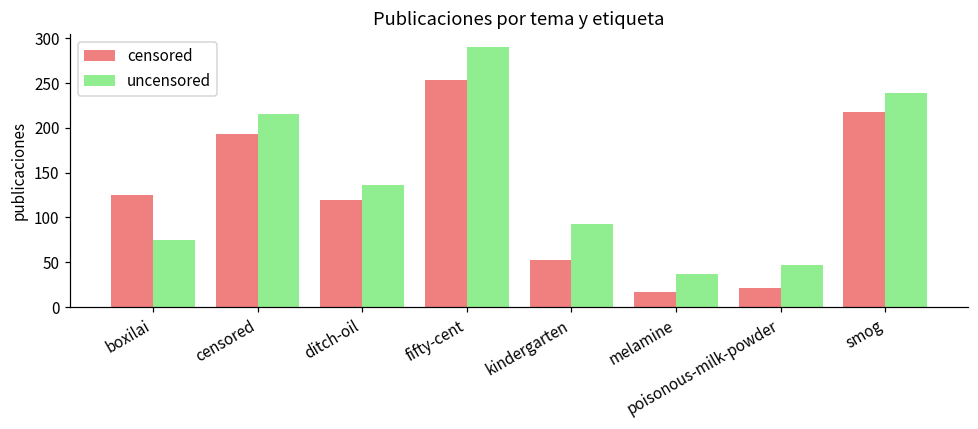

In [3]:
print('Total:', len(df), '| censored:', (df.label == 1).sum(),
      f'({(df.label == 1).mean() * 100:.1f} %)')

tab = df.pivot_table(index='tema', columns='etiqueta', values='texto_zh', aggfunc='count', fill_value=0)
tab['total'] = tab.sum(axis=1)
tab['% censored'] = (tab['censored'] / tab['total'] * 100).round(1)
tab.loc['TOTAL'] = [tab['censored'].sum(), tab['uncensored'].sum(), tab['total'].sum(),
                    round(tab['censored'].sum() / tab['total'].sum() * 100, 1)]
display(tab)

t = tab.drop('TOTAL')
x = np.arange(len(t)); w = 0.4
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w/2, t['censored'], w, color=col['censored'], label='censored')
ax.bar(x + w/2, t['uncensored'], w, color=col['uncensored'], label='uncensored')
ax.set_xticks(x)
ax.set_xticklabels(t.index, rotation=30, ha='right')
ax.set_ylabel('publicaciones')
ax.set_title('Publicaciones por tema y etiqueta'); ax.legend()
plt.tight_layout()
plt.show()

## Verificación contra la tabla de conteos de Ng et al.

Los conteos son de la Tabla 1 cruda del artículo. Tras depurar pueden faltar algunas publicaciones (duplicados y contradicciones).

In [4]:
tabla1 = pd.DataFrame(
    {'artículo_censored': [223, 120, 49, 195, 258, 125, 53],
     'artículo_uncensored': [240, 138, 85, 216, 290, 75, 94]},
    index=['smog', 'ditch-oil', 'milk-scandal', 'censored', 'fifty-cent', 'boxilai', 'kindergarten'])

g = df.assign(grupo=df['tema'].replace({'melamine': 'milk-scandal',
                                        'poisonous-milk-powder': 'milk-scandal'}))
conteo = g.pivot_table(index = 'grupo', columns = 'etiqueta', values = 'texto_zh',
                       aggfunc = 'count', fill_value = 0).rename(columns = lambda c: f'CSV_{c}')

cmp = tabla1.join(conteo, how='left').fillna(0).astype(int)
cmp['dif. censored'] = cmp['CSV_censored'] - cmp['artículo_censored']
cmp['dif. uncensored'] = cmp['CSV_uncensored'] - cmp['artículo_uncensored']
display(cmp)

,artículo_censored,artículo_uncensored,CSV_censored,CSV_uncensored,dif. censored,dif. uncensored
smog,223,240,218,239,-5,-1
ditch-oil,120,138,119,136,-1,-2
milk-scandal,49,85,38,84,-11,-1
censored,195,216,193,215,-2,-1
fifty-cent,258,290,253,290,-5,0
boxilai,125,75,125,75,0,0
kindergarten,53,94,53,93,0,-1


## Detección de caracteres invisibles

Este análisis no busca un carácter concreto. Revisa todos los caracteres del texto crudo y ordena los que más difieren entre clases. El carácter problemático debe salir del propio proceso.

1. **Escaneo sin supuestos.** Se listan todos los caracteres distintos del texto original, excepto letras y dígitos (categorías Unicode `L*` y `N*`), que se revisaron en la sección de limpieza.
2. **Presencia por clase.** Para cada carácter se calcula el porcentaje de publicaciones censuradas y no censuradas que lo contienen.
3. **Ordenar por diferencia.** Se ordena por la diferencia absoluta entre clases, en puntos porcentuales. Un carácter que aparece en muchas publicaciones de una clase y casi nada en la otra no depende del contenido, sino de la captura.
4. **Inspeccionar con `repr`.** Un carácter invisible no se ve en pantalla. Se muestra su representación para confirmar de qué carácter se trata.

In [5]:
def escanear_caracteres(textos_por_clase):
    """Presencia (%) de cada carácter no alfanumérico por clase, ordenada por diferencia entre clases."""
    vocab = set()
    for textos in textos_por_clase.values(): vocab |= set(''.join(textos))
    
    vocab = {c for c in vocab if unicodedata.category(c)[0] not in 'LN'}

    filas = []
    for c in vocab:
        fila = {'carácter': repr(c), 'código': f'U+{ord(c):04X}',
                'categoría': unicodedata.category(c), 'nombre': unicodedata.name(c, '?')}
    
        for e, textos in textos_por_clase.items():
    
            fila[f'% {e}'] = round(textos.str.contains(c, regex=False).mean() * 100, 2)
    
        filas.append(fila)

    out = pd.DataFrame(filas)
    out['diferencia (pp)'] = (out['% censored'] - out['% uncensored']).abs().round(2)
    return out.sort_values('diferencia (pp)', ascending=False).reset_index(drop=True)

textos_crudos = {e: df.loc[df.etiqueta == e, 'texto_original'].fillna('')
                 for e in ['censored', 'uncensored']}
escaneo = escanear_caracteres(textos_crudos)
display(escaneo.head(10))

,carácter,código,categoría,nombre,% censored,% uncensored,diferencia (pp)
0,'\u200b',U+200B,Cf,ZERO WIDTH SPACE,2.20,60.42,58.22
1,' ',U+0020,Zs,SPACE,25.33,73.41,48.08
2,'。',U+3002,Po,IDEOGRAPHIC FULL STOP,71.07,56.45,14.62
3,'，',U+FF0C,Po,FULLWIDTH COMMA,89.39,80.57,8.82
4,'：',U+FF1A,Po,FULLWIDTH COLON,16.72,8.22,8.50
5,'？',U+FF1F,Po,FULLWIDTH QUESTION MARK,29.83,23.76,6.07
6,'、',U+3001,Po,IDEOGRAPHIC COMMA,22.02,16.17,5.85
7,'；',U+FF1B,Po,FULLWIDTH SEMICOLON,10.01,4.42,5.59
8,'”',U+201D,Pf,RIGHT DOUBLE QUOTATION MARK,17.42,13.07,4.35
9,'“',U+201C,Pi,LEFT DOUBLE QUOTATION MARK,17.32,13.43,3.89


In [6]:
# Inspección del carácter con mayor diferencia entre clases
top = escaneo.iloc[0]
print('Carácter con mayor diferencia:', top['código'], top['nombre'],
      f"| censored {top['% censored']} % vs uncensored {top['% uncensored']} %")

caracter = chr(int(top['código'][2:], 16))
ejemplos = df.loc[df['texto_original'].fillna('').str.contains(caracter, regex = False), 'texto_original']

for t in ejemplos.head(3): print(repr(t[:60]))

Carácter con mayor diferencia: U+200B ZERO WIDTH SPACE | censored 2.2 % vs uncensored 60.42 %
'怪不得第一次听薄熙来名字的时候感觉熟悉又陌生 原来是希伯来人作怪 \u200b'
'大连肃清薄熙来流毒。 \u200b'
'看了下，几乎关于L U WE I事件的所有微博，或原文被屏蔽，或评论都被关闭了，转发也受限制。谁干的？某权力部门还是新浪'


## Limpieza y sesgos de captura

Se revisa qué rasgos superficiales siguen presentes tras la limpieza, y cuántas publicaciones traían `\u200b`.

In [7]:
pat = {'URL': r'https?://|www\.', 'mención @': r'@\S', 'latinas': r'[A-Za-z]', 'dígitos': r'\d'}
sup = pd.DataFrame({k: df['texto_zh'].str.contains(v, regex=True).groupby(df['etiqueta']).mean() * 100
                    for k, v in pat.items()}).round(1).T
sup.columns.name = '% de publicaciones con...'
display(sup)

zw = df.groupby('etiqueta')['tiene_zw'].agg(['sum', 'count'])
zw['%'] = (zw['sum'] / zw['count'] * 100).round(1)
print('Publicaciones que con \\u200b antes de limpiar:')
display(zw)

% de publicaciones con...,censored,uncensored
URL,0.0,0.0
mención @,0.0,0.0
latinas,13.2,12.1
dígitos,18.6,18.9


Publicaciones que con \u200b antes de limpiar:


,sum,count,%
etiqueta,,,
censored,22,999,2.2
uncensored,684,1132,60.4


## Longitud

Sesgo conocido del corpus: las censuradas son más cortas. Se compara la distribución y la mediana por tema.

,count,mean,std,min,50%,90%,99%,max
etiqueta,,,,,,,,
censored,999.0,91.3,42.7,5.0,100.0,140.0,147.0,161.0
uncensored,1132.0,85.6,70.1,5.0,71.0,150.0,332.5,637.0


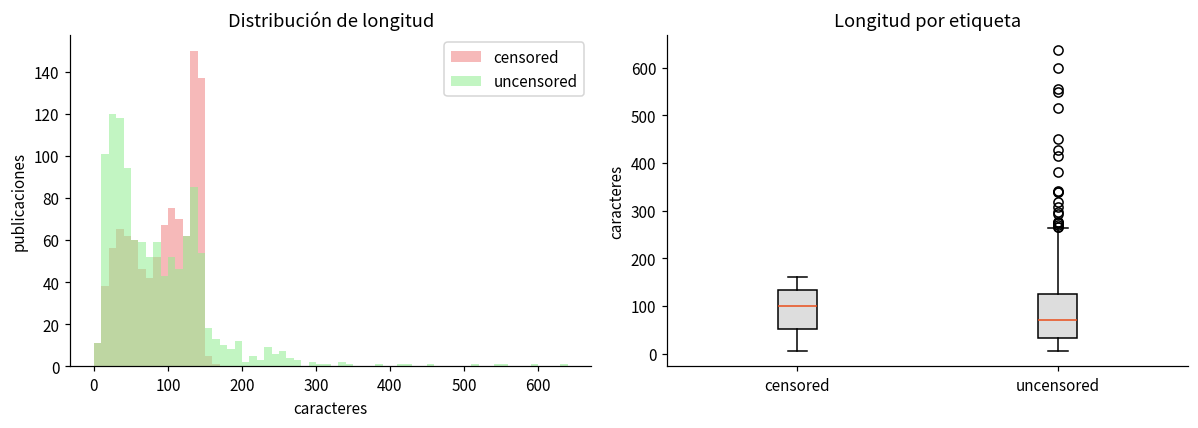

etiqueta,censored,uncensored
tema,,
boxilai,98.0,122.0
censored,83.0,44.0
ditch-oil,114.0,75.5
fifty-cent,85.0,79.0
kindergarten,111.0,139.0
melamine,134.0,88.0
poisonous-milk-powder,134.0,85.0
smog,108.0,49.0


In [8]:
display(df.groupby('etiqueta')['longitud'].describe(percentiles = [.5, .9, .99]).round(1))

fig, axs = plt.subplots(1, 2, figsize = (11, 4))
bins = np.arange(0, df['longitud'].max() + 10, 10)

for e in ['censored', 'uncensored']:

    axs[0].hist(df.loc[df.etiqueta == e, 'longitud'], bins=bins, alpha=.55, color=col[e], label=e)

axs[0].set_xlabel('caracteres'); axs[0].set_ylabel('publicaciones')
axs[0].legend()
axs[0].set_title('Distribución de longitud')
axs[1].boxplot([df.loc[df.etiqueta == e, 'longitud'] for e in ['censored', 'uncensored']],
               patch_artist = True, boxprops = dict(facecolor = '#ddd'), 
               medianprops = dict(color = naranja))

axs[1].set_xticks([1, 2]) 
axs[1].set_xticklabels(['censored', 'uncensored'])
axs[1].set_ylabel('caracteres')
axs[1].set_title('Longitud por etiqueta')
plt.tight_layout()
plt.show()

med = df.pivot_table(index = 'tema', columns = 'etiqueta', values = 'longitud', aggfunc = 'median')
display(med.round(1))

## Palabras más frecuentes por clase

Conteo de frecuencias de palabras de dos o más caracteres chinos, segmentadas con jieba.

In [9]:
han = re.compile(r'^[\u4e00-\u9fff]{2,}$')
df['tokens'] = df['texto_zh'].apply(lambda s: [t for t in jieba.lcut(s) if han.match(t)])

cnt = {e: Counter(t for toks in df.loc[df.etiqueta == e, 'tokens'] for t in toks)
       for e in ['censored', 'uncensored']}

print('Tokens por clase:', {e: sum(c.values()) for e, c in cnt.items()})
print('Vocabulario por clase:', {e: len(c) for e, c in cnt.items()})

top = pd.DataFrame({e: [f'{w} ({n})' for w, n in cnt[e].most_common(20)] for e in cnt})
display(top)

Tokens por clase: {'censored': 27978, 'uncensored': 29775}
Vocabulario por clase: {'censored': 10189, 'uncensored': 10417}


,censored,uncensored
0,五毛 (331),五毛 (341)
1,屏蔽 (209),屏蔽 (222)
2,一个 (191),新浪 (211)
3,中国 (187),地沟油 (180)
4,薄熙来 (177),一个 (167)
5,没有 (154),我们 (164)
6,地沟油 (145),中国 (160)
7,不是 (122),红黄蓝 (157)
8,就是 (118),没有 (155)
9,我们 (117),幼儿园 (146)


## Frecuencia documental por clase

La frecuencia bruta favorece a los temas más grandes. Aquí se mide en qué proporción de publicaciones aparece cada palabra, dentro de cada clase. Solo se consideran palabras con al menos 10 publicaciones en total.

In [10]:
n_c = (df.etiqueta == 'censored').sum()
n_u = (df.etiqueta == 'uncensored').sum()

pub_c = Counter(w for toks in df.loc[df.etiqueta == 'censored', 'tokens'] for w in set(toks))
pub_u = Counter(w for toks in df.loc[df.etiqueta == 'uncensored', 'tokens'] for w in set(toks))

fd = pd.DataFrame({'n censored': pd.Series(pub_c), 'n uncensored': pd.Series(pub_u)}).fillna(0).astype(int)
fd = fd[fd.sum(axis = 1) >= 10].copy()
fd['% censored'] = (fd['n censored'] / n_c * 100).round(1)
fd['% uncensored'] = (fd['n uncensored'] / n_u * 100).round(1)
fd['dif (pp)'] = (fd['% censored'] - fd['% uncensored']).round(1)

top_c = fd.sort_values('dif (pp)', ascending = False).head(15)
top_u = fd.sort_values('dif (pp)').head(15)

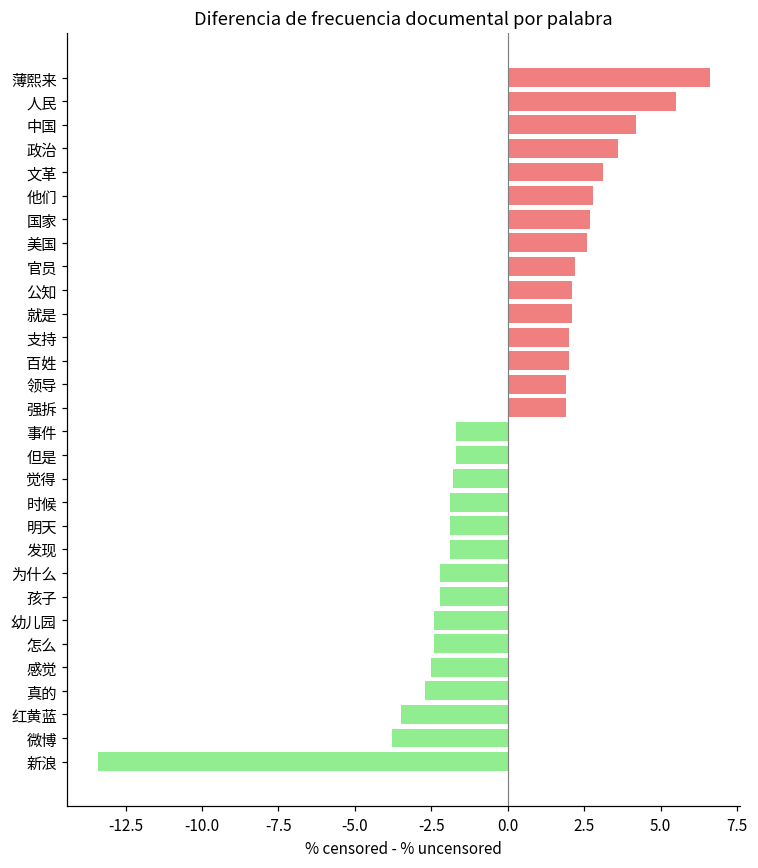

In [11]:
both = pd.concat([top_c, top_u])
both = both[~both.index.duplicated()].sort_values('dif (pp)')
colores = [col['censored'] if d > 0 else col['uncensored'] for d in both['dif (pp)']]

fig, ax = plt.subplots(figsize = (7, 8))
ax.barh(both.index, both['dif (pp)'], color=colores)
ax.axvline(0, color = 'gray', lw = 0.8)
ax.set_xlabel('% censored - % uncensored')
ax.set_title('Diferencia de frecuencia documental por palabra')
plt.tight_layout()
plt.show()

## N-gramas de caracteres y de palabras

Bigramas de caracteres chinos (sin puntuación ni dígitos) y bigramas de palabras segmentadas con jieba, por clase. Se reportan el total, los distintos y los 15 más frecuentes.

In [12]:
han_only = df['texto_zh'].str.replace(r'[^\u4e00-\u9fff]', '', regex = True)

def ngramas_caracteres(textos, n = 2):

    c = Counter()
    for s in textos: c.update(s[i:i + n] for i in range(len(s) - n + 1))

    return c

def bigramas_palabras(tokens):
    c = Counter()
    for toks in tokens: c.update(zip(toks, toks[1:]))
    
    return c

resumen, tops_char, tops_pal = {}, {}, {}

for e in ['censored', 'uncensored']:

    cc = ngramas_caracteres(han_only[df.etiqueta == e], 2)
    cp = bigramas_palabras(df.loc[df.etiqueta == e, 'tokens'])
    resumen[e] = {'bigramas de caracteres (total)': sum(cc.values()),
                  'bigramas de caracteres (distintos)': len(cc),
                  'bigramas de palabras (total)': sum(cp.values()),
                  'bigramas de palabras (distintos)': len(cp)}
    tops_char[e] = [f'{g} ({n})' for g, n in cc.most_common(15)]
    tops_pal[e] = [f"{a}·{b} ({n})" for (a, b), n in cp.most_common(15)]

display(pd.DataFrame(resumen).T)
display(pd.DataFrame(tops_char))
display(pd.DataFrame(tops_pal))

,bigramas de caracteres (total),bigramas de caracteres (distintos),bigramas de palabras (total),bigramas de palabras (distintos)
censored,78127,40023,26979,24840
uncensored,83159,41157,28644,26180


,censored,uncensored
0,五毛 (345),五毛 (348)
1,雾霾 (291),毛党 (294)
2,屏蔽 (212),雾霾 (284)
3,中国 (203),屏蔽 (235)
4,一个 (203),新浪 (214)
5,薄熙 (178),什么 (213)
6,熙来 (178),一个 (183)
7,没有 (166),地沟 (183)
8,地沟 (145),中国 (182)
9,沟油 (145),沟油 (182)


,censored,uncensored
0,红黄蓝·幼儿园 (29),红黄蓝·幼儿园 (61)
1,政治·活动 (17),新浪·屏蔽 (53)
2,组织·政治 (15),虐童·事件 (26)
3,不是·为了 (13),周永康·薄熙来 (21)
4,限制·华人 (11),北京·红黄蓝 (20)
5,五毛·自干 (11),新浪·微博 (16)
6,周永康·薄熙来 (9),幼儿园·虐童 (16)
7,全国·人民 (8),毒奶粉·坐牢 (15)
8,人民·群众 (8),家长·反映 (11)
9,因为·他们 (8),屏蔽·微博 (10)


## Representación en pinyin

Cada carácter viene con su transcripción fonética (columna `pinyin`, con tono). Al quitar el tono, varios caracteres distintos comparten la misma sílaba: son homófonos. Por eso hay menos sílabas distintas que caracteres distintos. Esa ambigüedad es el espacio donde se esconden los eufemismos por homofonía; el artículo de King, Pan y Roberts (2013) cita el caso de «hexie», que se escribe como 河蟹 («cangrejo de río») para referirse a 和谐 («armonía»).

Solo se cuantifica aquí la compresión. Las publicaciones cuyo número de sílabas no coincide con el número de caracteres chinos se excluyen del mapeo carácter–sílaba (son las no alineadas).

In [13]:
def silabas(p):
    return [re.sub(r'\d', '', t) for t in p.split() if re.fullmatch(r'[a-z]+[1-5]?', t)]

df['silabas'] = df['pinyin'].apply(silabas)

filas, pares, alineadas = {}, Counter(), 0

for e in ['censored', 'uncensored']:

    sub = df.loc[df.etiqueta == e]
    han = re.findall(r'[\u4e00-\u9fff]', ''.join(sub['texto_zh']))
    sil = Counter(s for lst in sub['silabas'] for s in lst)
    filas[e] = {'caracteres chinos (tokens)': len(han),
                'sílabas (tokens)': sum(sil.values()),
                'caracteres distintos': len(set(han)),
                'sílabas distintas (sin tono)': len(sil),
                'caracteres distintos por sílaba': round(len(set(han)) / len(sil), 2)}

for txt, p in zip(df['texto_zh'], df['pinyin']):

    han = re.findall(r'[\u4e00-\u9fff]', txt)
    sil = silabas(p)

    if len(han) == len(sil):

        alineadas = alineadas + 1
        pares.update(zip(sil, han))

display(pd.DataFrame(filas).T)
print(f'Publicaciones alineadas carácter-sílaba: {alineadas} de {len(df)} ({alineadas / len(df) * 100:.1f} %)')

por_silaba = {}
for (s, c), n in pares.items():
    
    por_silaba.setdefault(s, Counter())[c] += n

homofonos = sorted(por_silaba.items(), key=lambda kv: -len(kv[1]))[:10]
display(pd.DataFrame({'sílaba': [s for s, _ in homofonos],
                      'caracteres distintos': [len(v) for _, v in homofonos],
                      'ejemplos más frecuentes': [''.join(c for c, _ in v.most_common(6)) for _, v in homofonos]}))

,caracteres chinos (tokens),sílabas (tokens),caracteres distintos,sílabas distintas (sin tono),caracteres distintos por sílaba
censored,79126.0,79156.0,2835.0,406.0,6.98
uncensored,84291.0,84333.0,2981.0,429.0,6.95


Publicaciones alineadas carácter-sílaba: 2079 de 2131 (97.6 %)


,sílaba,caracteres distintos,ejemplos más frecuentes
0,ji,56,己几机记基及
1,shi,51,是事时实师市
2,yi,42,一以意已义依
3,zhi,40,知之只治制直
4,fu,38,府腐服富复福
5,yu,38,于与育余遇鱼
6,xi,35,熙西息吸习希
7,jian,35,件见间监建奸
8,wei,33,为微委位未维
9,qi,32,起气其期奇企


## Pinyin: tonos, frecuencia y n-gramas de sílabas

Esta sección trabaja solo con la columna `pinyin`. Se analiza la sílaba como unidad: cómo se distribuyen los tonos, qué sílabas aparecen más en cada clase, qué bigramas y trigramas de sílabas son frecuentes, cuánta ambigüedad homofónica tiene el texto de cada clase y si la representación en sílabas sirve para clasificar frente a palabras o caracteres.

Los n-gramas de sílabas se forman dentro de cada publicación, pero sin puntuación; por eso pueden cruzar límites de oración.

,sílabas con tono (tokens),tipos con tono,tipos sin tono,tipos / tokens con tono (%),% tono neutro
censored,79156.0,1092.0,406.0,1.38,6.5
uncensored,84333.0,1122.0,429.0,1.33,7.2


,censored,uncensored
tono 1,18.9,19.2
tono 2,22.6,22.2
tono 3,18.3,18.2
tono 4,33.7,33.1
neutro,6.5,7.2


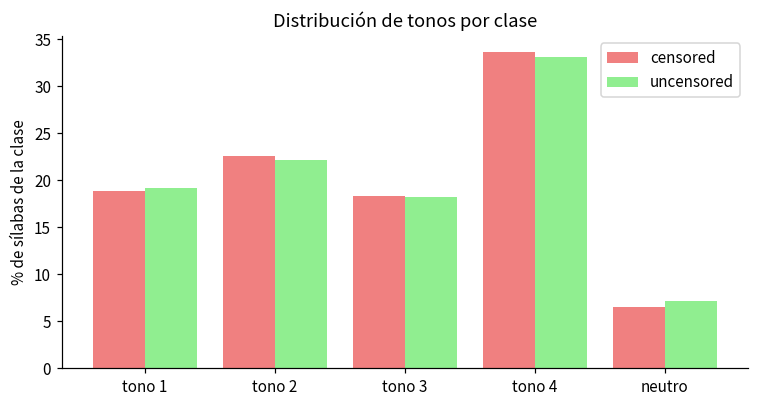

In [14]:
def silabas_con_tono(p):
    return [t for t in p.split() if re.fullmatch(r'[a-z]+[1-5]?', t)]

def tono(t):
    return t[-1] if t[-1] in '1234' else 'neutro'

df['sil_tono'] = df['pinyin'].apply(silabas_con_tono)

filas, dist_tono = {}, {}
for e in ['censored', 'uncensored']:
    sub = df.loc[df.etiqueta == e]
    con = Counter(t for lst in sub['sil_tono'] for t in lst)
    sin = Counter(s for lst in sub['silabas'] for s in lst)
    tn = Counter(tono(t) for lst in sub['sil_tono'] for t in lst)
    n = sum(con.values())
    filas[e] = {'sílabas con tono (tokens)': n,
                'tipos con tono': len(con),
                'tipos sin tono': len(sin),
                'tipos / tokens con tono (%)': round(len(con) / n * 100, 2),
                '% tono neutro': round(tn['neutro'] / n * 100, 1)}
    dist_tono[e] = tn

display(pd.DataFrame(filas).T)

tab_tono = pd.DataFrame(dist_tono).reindex(['1', '2', '3', '4', 'neutro']).fillna(0)
pct_tono = (tab_tono / tab_tono.sum() * 100).round(1)
pct_tono.index = ['tono 1', 'tono 2', 'tono 3', 'tono 4', 'neutro']
display(pct_tono)

x = np.arange(len(pct_tono)); w = 0.4
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(x - w/2, pct_tono['censored'], w, color=col['censored'], label='censored')
ax.bar(x + w/2, pct_tono['uncensored'], w, color=col['uncensored'], label='uncensored')
ax.set_xticks(x); ax.set_xticklabels(pct_tono.index)
ax.set_ylabel('% de sílabas de la clase'); ax.set_title('Distribución de tonos por clase')
ax.legend(); plt.tight_layout(); plt.show()

### Frecuencia documental de sílabas

Igual que con las palabras: en qué proporción de publicaciones aparece cada sílaba (sin tono), dentro de cada clase. Solo se consideran sílabas en al menos 10 publicaciones.

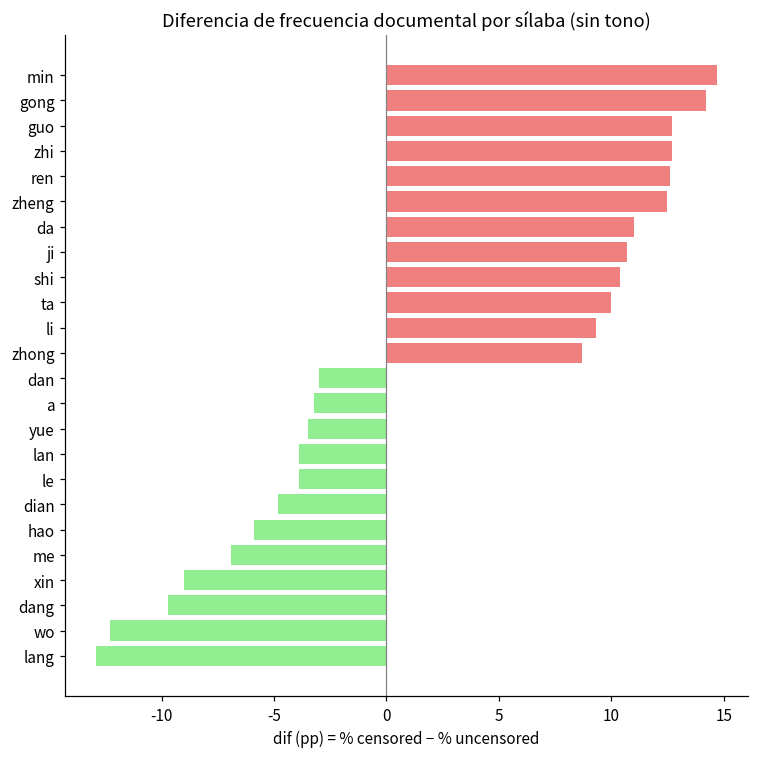

,% censored,% uncensored,dif (pp)
min,26.1,11.4,14.7
gong,34.5,20.3,14.2
zhi,60.8,48.1,12.7
guo,48.7,36.0,12.7
ren,56.1,43.5,12.6
zheng,34.8,22.3,12.5
da,44.2,33.2,11.0
ji,54.0,43.3,10.7
shi,86.0,75.6,10.4
ta,25.6,15.6,10.0


,% censored,% uncensored,dif (pp)
lang,5.7,18.6,-12.9
wo,30.0,42.3,-12.3
dang,22.5,32.2,-9.7
xin,32.7,41.7,-9.0
me,21.2,28.1,-6.9
hao,20.4,26.3,-5.9
dian,13.3,18.1,-4.8
le,53.2,57.1,-3.9
lan,7.8,11.7,-3.9
yue,7.7,11.2,-3.5


In [ ]:
def frecuencia_documental(listas, min_docs=10):
    t = pd.DataFrame({e: pd.Series(Counter(x for lst in v for x in set(lst)))
                      for e, v in listas.items()}).fillna(0).astype(int)
    t = t[t.sum(axis=1) >= min_docs].copy()
    t['% censored'] = (t['censored'] / len(listas['censored']) * 100).round(1)
    t['% uncensored'] = (t['uncensored'] / len(listas['uncensored']) * 100).round(1)
    t['dif (pp)'] = (t['% censored'] - t['% uncensored']).round(1)
    return t

fs = frecuencia_documental({e: df.loc[df.etiqueta == e, 'silabas'] for e in ['censored', 'uncensored']})

top_c = fs.sort_values('dif (pp)', ascending=False).head(12)
top_u = fs.sort_values('dif (pp)').head(12)

both = pd.concat([top_c, top_u]); both = both[~both.index.duplicated()].sort_values('dif (pp)')
colores = [col['censored'] if d > 0 else col['uncensored'] for d in both['dif (pp)']]

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(both.index, both['dif (pp)'], color=colores)
ax.axvline(0, color='gray', lw=0.8)
ax.set_xlabel('dif (pp) = % censored - % uncensored')
ax.set_title('Diferencia de frecuencia documental por sílaba (sin tono)')
plt.tight_layout(); plt.show()

display(top_c[['% censored', '% uncensored', 'dif (pp)']])
display(top_u[['% censored', '% uncensored', 'dif (pp)']])

### N-gramas de sílabas

Bigramas y trigramas de sílabas sin tono, con su total, número de distintos y los 15 más frecuentes por clase.

In [16]:
def ngramas_silabas(listas, n):
    c = Counter()
    for lst in listas:
        c.update(' '.join(lst[i:i + n]) for i in range(len(lst) - n + 1))
    return c

resumen, tops = {}, {}
for n in [2, 3]:
    for e in ['censored', 'uncensored']:
        c = ngramas_silabas(df.loc[df.etiqueta == e, 'silabas'], n)
        resumen[(f'{n}-gramas', e)] = {'total': sum(c.values()), 'distintos': len(c),
                                       'distintos / total (%)': round(len(c) / sum(c.values()) * 100, 1)}
        tops[(f'{n}-gramas', e)] = [f'{g} ({k})' for g, k in c.most_common(15)]

display(pd.DataFrame(resumen).T)
display(pd.DataFrame({e: tops[('2-gramas', e)] for e in ['censored', 'uncensored']}))
display(pd.DataFrame({e: tops[('3-gramas', e)] for e in ['censored', 'uncensored']}))

total  distintos  distintos / total (%)
2-gramas censored    78157.0    25841.0                   33.1
         uncensored  83201.0    26496.0                   31.8
3-gramas censored    77158.0    62232.0                   80.7
         uncensored  82069.0    65309.0                   79.6

,censored,uncensored
0,wu mao (346),wu mao (348)
1,wu mai (291),mao dang (295)
2,ping bi (213),wu mai (284)
3,yi ge (207),ping bi (236)
4,zhong guo (205),shen me (220)
5,bao xi (179),xin lang (215)
6,xi lai (178),de shi (188)
7,mei you (166),zhong guo (186)
8,de shi (156),yi ge (186)
9,bu shi (147),di gou (186)


,censored,uncensored
0,bao xi lai (176),wu mao dang (294)
1,di gou you (145),di gou you (184)
2,hong huang lan (74),hong huang lan (158)
3,bei ping bi (68),you er yuan (146)
4,you er yuan (51),bao xi lai (99)
5,de wu mao (45),ping bi le (73)
6,du nai fen (40),du nai fen (66)
7,zi gan wu (39),wei shen me (63)
8,zhou yong kang (35),huang lan you (61)
9,wei shen me (35),lan you er (61)


### Ambigüedad homofónica por clase

Cada sílaba (sin tono) puede corresponder a varios caracteres. La ambigüedad de una sílaba es el número de caracteres distintos que le corresponden en el corpus completo (calculado con el mapeo de la celda anterior). Aquí se promedia esa ambigüedad sobre los tokens de cada clase. Es una medida descriptiva del espacio en el que pueden ocurrir sustituciones por homofonía; no demuestra que existan eufemismos.

,tokens,ambigüedad media,ambigüedad mediana,% tokens con >= 5 caracteres posibles,% tokens con >= 10 caracteres posibles
censored,79156.0,15.54,12.0,87.9,62.3
uncensored,84333.0,15.24,11.0,87.3,61.5


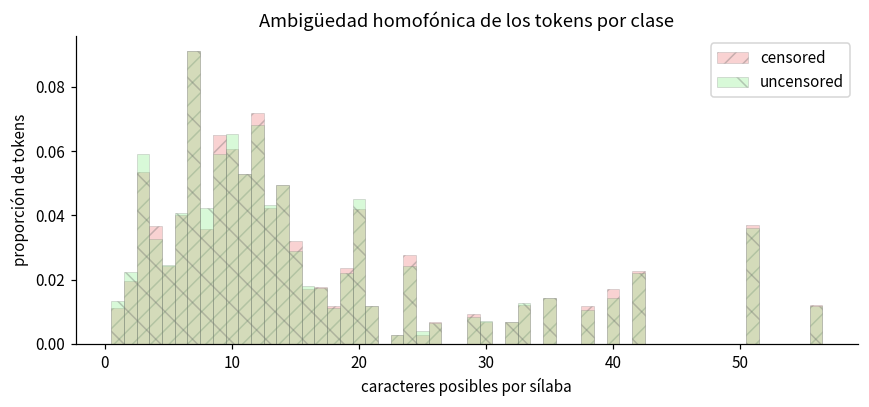

In [23]:
ambig = {s: len(v) for s, v in por_silaba.items()}

filas = {}
for e in ['censored', 'uncensored']:
    vals = np.array([ambig.get(s, 1) for lst in df.loc[df.etiqueta == e, 'silabas'] for s in lst])
    filas[e] = {'tokens': len(vals),
                'ambigüedad media': round(vals.mean(), 2),
                'ambigüedad mediana': float(np.median(vals)),
                '% tokens con >= 5 caracteres posibles': round((vals >= 5).mean() * 100, 1),
                '% tokens con >= 10 caracteres posibles': round((vals >= 10).mean() * 100, 1)}
display(pd.DataFrame(filas).T)

patron = {'censored': '//', 'uncensored': '\\'}

fig, ax = plt.subplots(figsize = (8, 3.8))
binss = np.arange(1, max(ambig.values()) + 2) - 0.5

for e in ['censored', 'uncensored']:
    vals = [ambig.get(s, 1) for lst in df.loc[df.etiqueta == e, 'silabas'] for s in lst]
    ax.hist(vals, bins = binss, density = True, color = col[e], alpha = 0.35,
            hatch = patron[e], edgecolor = 'dimgray', linewidth = 0.4, label = e)

ax.set_xlabel('caracteres posibles por sílaba')
ax.set_ylabel('proporción de tokens')
ax.set_title('Ambigüedad homofónica de los tokens por clase')
ax.legend()
plt.tight_layout()
plt.show()

### Comparación de representaciones

Se compara qué representación separa mejor las clases, con 5 pliegues estratificados (semilla 43), F1 macro como métrica y dos modelos vistos en el curso: Naive Bayes multinomial sobre conteos y regresión logística sobre TF-IDF. Se ajustan vectorizador y modelo dentro de cada pliegue para no filtrar información del conjunto de prueba.

Esto compara representaciones, no es un modelo final: la partición no es cronológica porque el CSV no trae fecha.

In [ ]:
def bigramas_lista(lst):
    return [f'{a}_{b}' for a, b in zip(lst, lst[1:])]

representaciones = {
    'palabras (jieba)': df['tokens'].tolist(),
    'caracteres chinos': [list(s) for s in han_only],
    'sílabas sin tono': df['silabas'].tolist(),
    'sílabas con tono': df['sil_tono'].tolist(),
    'bigramas de sílabas': [bigramas_lista(l) for l in df['silabas']],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=43)
y = df['label'].values

filas = []
for nombre, docs in representaciones.items():
    X = np.empty(len(docs), dtype=object)
    for i, d in enumerate(docs):
        X[i] = d
    nb_pipe = make_pipeline(CountVectorizer(analyzer=lambda x: x), MultinomialNB())
    lr_pipe = make_pipeline(TfidfVectorizer(analyzer=lambda x: x, min_df=2),
                            LogisticRegression(max_iter=2000))
    s_nb = cross_val_score(nb_pipe, X, y, cv=cv, scoring='f1_macro')
    s_lr = cross_val_score(lr_pipe, X, y, cv=cv, scoring='f1_macro')
    filas.append({'representación': nombre,
                  'tipos distintos': len({t for d in docs for t in d}),
                  'NB F1 macro (media)': round(s_nb.mean(), 3), 'NB desv.': round(s_nb.std(), 3),
                  'LR F1 macro (media)': round(s_lr.mean(), 3), 'LR desv.': round(s_lr.std(), 3)})

display(pd.DataFrame(filas).set_index('representación'))

,tipos distintos,NB F1 macro (media),NB desv.,LR F1 macro (media),LR desv.
representación,,,,,
palabras (jieba),16719,0.738,0.015,0.729,0.013
caracteres chinos,3423,0.742,0.020,0.752,0.017
sílabas sin tono,440,0.693,0.020,0.715,0.014
sílabas con tono,1182,0.717,0.013,0.747,0.012
bigramas de sílabas,37937,0.766,0.006,0.773,0.017


### Resumen pinyin

- **Tonos.** La distribución de tonos casi no cambia entre clases (el tono 4 es 33.7 % en censurados y 33.1 % en no censurados; el neutro, 6.5 % y 7.2 %). Los tonos no son un rasgo útil por sí mismos.
- **Sílabas frecuentes.** Por frecuencia documental, *min*, *gong*, *zhi*, *guo* y *ren* son más típicas de censurados. *lang* (de 新浪), *wo*, *dang*, *xin* y *me* son más típicas de no censurados. Esto coincide con lo observado en palabras: el léxico de plataforma pesa más en no censurados.
- **Bigramas y trigramas.** «wu mao dang» (五毛党) aparece en 294 publicaciones de no censurados. Los trigramas son muy dispersos: el 80 % de los trigramas son distintos entre sí, así que la mayoría aparece pocas veces.
- **Ambigüedad homofónica.** La ambigüedad media es casi igual entre clases (15.5 en censurados y 15.2 en no censurados). Con esta métrica, la homofonía no distingue las clases; cualquier diferencia de uso de eufemismos tendría que buscarse en otra medida.
- **Comparación de representaciones.** Los bigramas de sílabas obtienen el mejor F1 macro (NB 0.766, LR 0.773), seguidos de caracteres (0.742 y 0.752) y palabras (0.738 y 0.729). Usar solo sílabas sin tono es lo que peor funciona (NB 0.693, LR 0.715): al quitar caracteres se pierde información. Una hipótesis es que los bigramas recuperan parte del contexto de palabras de varias sílabas, pero no se comprobó. Las diferencias entre representaciones son pequeñas, del orden de la desviación estándar, así que no conviene sobreinterpretarlas. Además, la partición es aleatoria, no cronológica, y publicaciones casi repetidas entre pliegues podrían inflar los resultados; conviene revisarlo antes de concluir.

## Categorías gramaticales (POS)

Etiquetado con `jieba.posseg`, con etiquetas de tipo ICTCLAS: 

`n` sustantivo 

`v` verbo 

`a` adjetivo

`d` adverbio

`r` pronombre

`p` preposición

`m` numeral

`c` conjunción

`nr` nombre de persona

`ns` lugar

`nt` organización

`uj` partícula 的

`ul` partícula de aspecto (了, 过…)

,censored,uncensored,dif (pp)
n,23.65,23.13,0.52
v,22.94,22.25,0.69
d,7.19,7.74,-0.55
r,6.73,7.12,-0.39
uj,5.17,5.36,-0.19
p,3.72,3.64,0.08
m,3.41,3.53,-0.12
a,3.11,3.38,-0.27
nr,3.06,2.77,0.29
c,2.96,2.97,-0.01


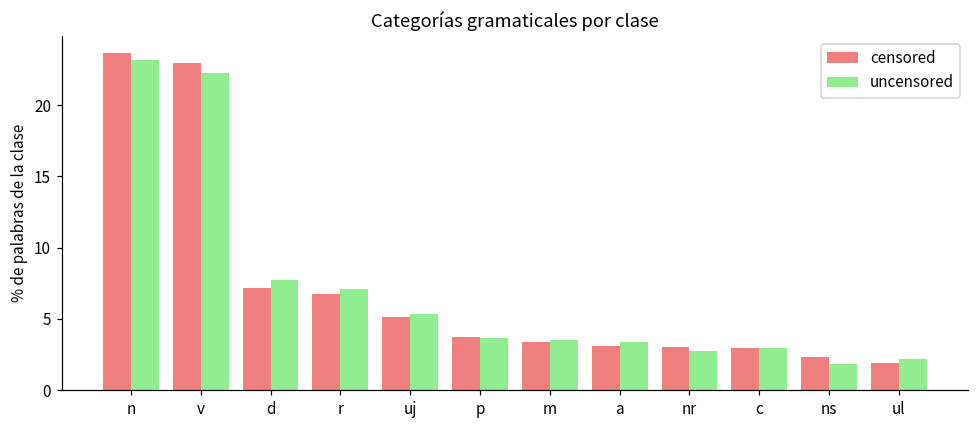

In [19]:
def etiquetas_pos(texto):
    
    return [p for w, p in pseg.lcut(texto) if re.fullmatch(r'[\u4e00-\u9fff]+', w)]

df['pos'] = df['texto_zh'].apply(etiquetas_pos)

conteo = {e: Counter(p for lst in df.loc[df.etiqueta == e, 'pos'] for p in lst)
          for e in ['censored', 'uncensored']}
total = {e: sum(c.values()) for e, c in conteo.items()}

pos_tab = pd.DataFrame({e: {k: round(v / total[e] * 100, 2) for k, v in conteo[e].items()}
                        for e in conteo}).fillna(0)
pos_tab['dif (pp)'] = (pos_tab['censored'] - pos_tab['uncensored']).round(2)
pos_tab = pos_tab.sort_values('censored', ascending=False).head(12)
display(pos_tab)

x = np.arange(len(pos_tab))
w = 0.4
fig, ax = plt.subplots(figsize = (9, 4))
ax.bar(x - w/2, pos_tab['censored'], w, color = col['censored'], label = 'censored')
ax.bar(x + w/2, pos_tab['uncensored'], w, color = col['uncensored'], label = 'uncensored')
ax.set_xticks(x)
ax.set_xticklabels(pos_tab.index)
ax.set_ylabel('% de palabras de la clase')
ax.set_title('Categorías gramaticales por clase')
ax.legend()
plt.tight_layout()
plt.show()

## TF-IDF: términos característicos de cada clase

TF-IDF sobre las palabras segmentadas (términos en al menos 5 publicaciones). Para cada término se promedia su peso TF-IDF en las publicaciones de cada clase. La diferencia entre promedios indica qué términos pesan más en cada una. Es una lista descriptiva, no una prueba estadística.

In [20]:
vec = TfidfVectorizer(tokenizer = lambda x: x, preprocessor = lambda x: x, 
                      token_pattern = None, lowercase = False, min_df = 5)

X = vec.fit_transform(df['tokens'])
terminos = np.array(vec.get_feature_names_out())
y = df['label'].values

media_c = np.asarray(X[y == 1].mean(axis = 0)).ravel()
media_u = np.asarray(X[y == 0].mean(axis = 0)).ravel()
dif = media_c - media_u

idx_c = np.argsort(-dif)[:15]
idx_u = np.argsort(dif)[:15]
display(pd.DataFrame({
    'censored (media TF-IDF)': [f'{terminos[i]} ({media_c[i]:.3f})' for i in idx_c],
    'uncensored (media TF-IDF)': [f'{terminos[i]} ({media_u[i]:.3f})' for i in idx_u]}))

,censored (media TF-IDF),uncensored (media TF-IDF)
0,薄熙来 (0.028),新浪 (0.040)
1,人民 (0.015),微博 (0.023)
2,文革 (0.010),地沟油 (0.030)
3,政治 (0.013),感觉 (0.010)
4,中国 (0.024),明天 (0.009)
5,美国 (0.010),真的 (0.012)
6,他们 (0.016),为什么 (0.013)
7,公知 (0.010),红黄蓝 (0.017)
8,帖子 (0.007),怎么 (0.014)
9,国家 (0.011),幼儿园 (0.013)


## Línea base y sesgo de longitud

Dos referencias para dimensionar el problema, con validación cruzada K-fold estratificada (5 pliegues) y la métrica principal del proyecto (F1 macro):

1. **Clase mayoritaria.** Predice siempre «no censurado». Su F1 macro es el piso que cualquier modelo debe superar.
2. **Regresión logística con solo la longitud** (en escala logarítmica). Mide cuánta separación se obtiene sin leer el contenido. Si es alta, la longitud es un confusor que hay que controlar en los modelos.

La partición cronológica del plan no es posible porque el CSV no trae fecha; esta limitación se reporta en el documento.

In [21]:
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 43)

base = cross_val_score(DummyClassifier(strategy = 'most_frequent'),
                       np.zeros((len(df), 1)), df['label'], cv = cv, scoring = 'f1_macro')

solo_longitud = make_pipeline(StandardScaler(), LogisticRegression(max_iter = 1000))
lon = cross_val_score(solo_longitud, np.log1p(df[['longitud']].values), df['label'],
                      cv = cv, scoring = 'f1_macro')

display(pd.DataFrame({'modelo': ['clase mayoritaria', 'solo longitud (log)'],
                      'F1 macro (media)': [base.mean(), lon.mean()],
                      'desv. est.': [base.std(), lon.std()]}).round(3))

,modelo,F1 macro (media),desv. est.
0,clase mayoritaria,0.347,0.000
1,solo longitud (log),0.567,0.019


- **Balance por tema.** El porcentaje censurado va de 62.5 % (boxilai) a 30.9 % (poisonous-milk-powder). La validación debe estratificarse por etiqueta y reportarse por tema.
- **Longitud como confusor.** La mediana es de 100 caracteres en censuradas y de 71 en no censuradas. Con la longitud sola, la regresión logística llega a F1 macro de 0.566, frente a 0.347 de la clase mayoritaria. La dirección del efecto cambia por tema (en boxilai y kindergarten las censuradas son más cortas), así que debe controlarse en los modelos.
- **Léxico político frente a léxico de plataforma.** 薄熙来, 人民, 文革 y 政治 aparecen más en censuradas. 新浪 aparece en 16.3 % de las no censuradas y en 2.9 % de las censuradas. Esto sugiere un sesgo de fuente, pero es una hipótesis: el CSV no tiene columna de origen y no se puede confirmar aquí.
- **Gramática casi igual.** Las proporciones de categorías POS difieren como máximo 0.7 puntos porcentuales entre clases. La separación parece léxica, no sintáctica; esto depende de un etiquetador que aún no se ha validado.
- **Pinyin.** El 97.6 % de las publicaciones se alinea carácter–sílaba. Los caracteres distintos por sílaba son casi iguales en ambas clases (6.98 y 6.95).
- **Carácter U+200B.** Es la señal de captura más fuerte (60.4 % de no censuradas frente a 2.2 % de censuradas). Se conserva solo como bandera de control, no como rasgo.